# Практичне заняття 4.13
## Практичне використання репозиторіїв аналітичних моделей в межах індивідуальних (групових) проектів

Ноутбук складається з двох частин відповідно до плану заняття:

| Частина | Зміст | Що використано |
|---|---|---|
| **A. Індивідуальна робота** | Вибір попередньо навченої моделі з репозиторію моделей і її **fine-tuning** під власну задачу | `keras.applications.MobileNetV2` (ваги ImageNet — репозиторій Keras Applications, аналог TensorFlow Hub / PyTorch Model Zoo) |
| **B. Групова робота** | Розробка **RL-агента** для оптимізації логістичного маршруту в симульованому середовищі | власне середовище «маршрут постачання» + **Q-learning** і **DQN** (TensorFlow) |

**Задача частини A:** класифікація аерофото/знімків місцевості на **«сільська» (rural)** та **«міська» (urban)** — підзадача аналізу місцевості при плануванні маршрутів і розвідці. Дані — з репозиторію курсу (`Theme4/Group lesson 12`, 72 train + 20 val зображень).

In [1]:
# %pip install tensorflow pillow scikit-learn matplotlib seaborn pandas   # за потреби
import os, time, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 42
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


---
# Частина A. Transfer Learning з репозиторію попередньо навчених моделей

## A.1. Вибір моделі з репозиторію
| Кандидат (Keras Applications) | Параметрів | Top-1 ImageNet | Коментар |
|---|---:|---:|---|
| ResNet50 | 25.6 M | 74.9% | точна, але важка для CPU і для 72 зображень |
| EfficientNetB0 | 5.3 M | 77.1% | хороший компроміс |
| **MobileNetV2** | **3.5 M** | 71.3% | **обрано**: найлегша, швидко навчається на CPU, придатна для розгортання на edge-пристроях (БпЛА, планшет) |

З такою малою вибіркою (72 зображення) навчити глибоку мережу з нуля неможливо — саме тут transfer learning дає вирішальний ефект: використовуємо ознаки, вивчені на 1.2 млн зображень ImageNet.

## A.2. Підготовка даних

train (57, 224, 224, 3), val (15, 224, 224, 3), test (20, 224, 224, 3)
Класи у train: [28 29] | val: [8 7] | test: [10 10]


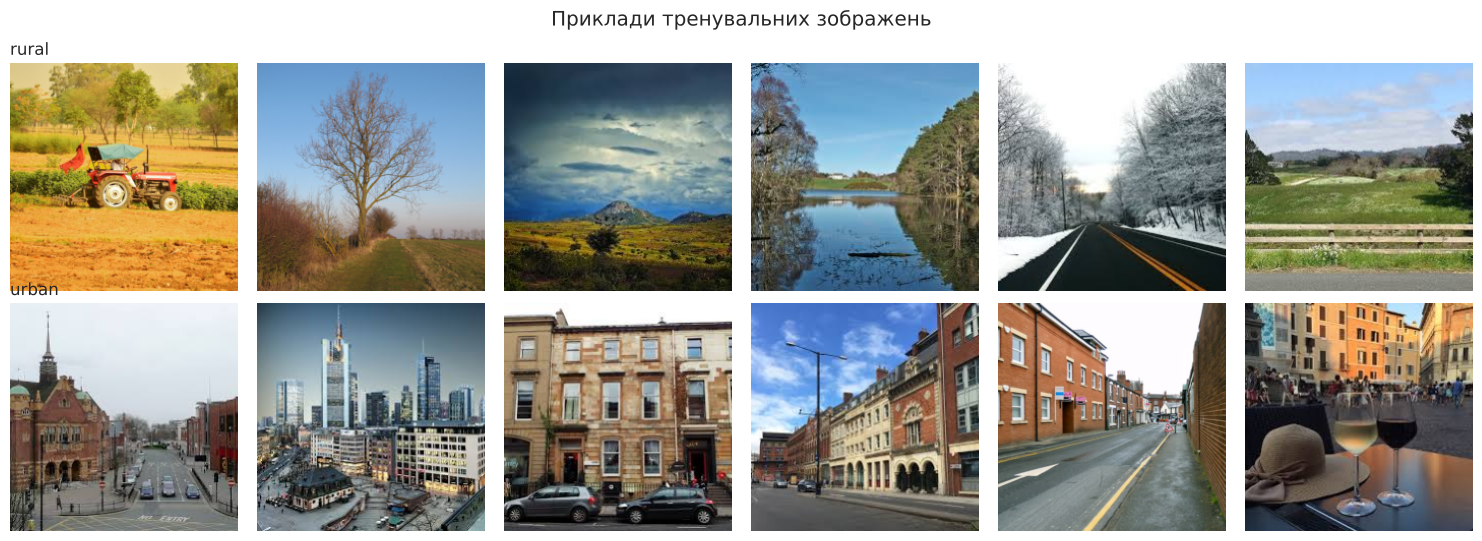

In [2]:
IMG = 224
DATA = Path("data")
CLASSES = ["rural", "urban"]

def load_folder(folder):
    X, y, names = [], [], []
    for label, cls in enumerate(CLASSES):
        for f in sorted((folder / cls).iterdir()):
            img = Image.open(f).convert("RGB").resize((IMG, IMG), Image.BILINEAR)
            X.append(np.asarray(img, dtype="float32")); y.append(label); names.append(f.name)
    return np.stack(X), np.array(y), names

X_all, y_all, _ = load_folder(DATA / "train")
X_test, y_test, test_names = load_folder(DATA / "val")      # папку val використовуємо як незалежний TEST
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
print(f"train {X_train.shape}, val {X_val.shape}, test {X_test.shape}")
print("Класи у train:", np.bincount(y_train), "| val:", np.bincount(y_val), "| test:", np.bincount(y_test))

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for r, cls in enumerate(CLASSES):
    for c, img in enumerate(X_train[y_train == r][:6]):
        axes[r, c].imshow(img.astype("uint8")); axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left")
plt.suptitle("Приклади тренувальних зображень"); plt.tight_layout(); plt.show()

**Протокол:** `train` (57) — навчання, `val` (15) — early stopping і вибір стратегії, окрема папка `val` з репозиторію (20 зображень) — **фінальний test**, який не бере участі в навчанні й налаштуванні.

**Аугментація** (тільки під час навчання): віддзеркалення, невеликі поворот і масштаб, зміна контрасту — збільшує ефективний розмір вибірки.

In [3]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

## A.3. Завантаження попередньо навченої MobileNetV2
Ваги ImageNet завантажуються з репозиторію Keras Applications. Якщо основне сховище недоступне, використовується офіційне дзеркало тих самих ваг на GitHub (автор реалізації MobileNetV2 для Keras).

In [4]:
def load_mobilenet_base():
    kwargs = dict(input_shape=(IMG, IMG, 3), include_top=False)
    try:
        return keras.applications.MobileNetV2(weights="imagenet", **kwargs), "keras-applications (imagenet)"
    except Exception as e:
        print("Основне сховище недоступне:", type(e).__name__)
        path = keras.utils.get_file(
            "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5",
            "https://github.com/JonathanCMitchell/mobilenet_v2_keras/releases/download/v1.1/"
            "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5")
        return keras.applications.MobileNetV2(weights=path, **kwargs), "github mirror (imagenet)"

base, source = load_mobilenet_base()
print("Ваги:", source, "| шарів:", len(base.layers), "| параметрів:", f"{base.count_params():,}")

Основне сховище недоступне: Exception


Ваги: github mirror (imagenet) | шарів: 154 | параметрів: 2,257,984


## A.4. Три стратегії (контрольоване порівняння)
1. **Scratch** — невелика CNN, навчена з нуля (baseline: що буде без репозиторію моделей).
2. **Feature extraction** — MobileNetV2 повністю **заморожена**, навчається лише новий класифікатор (`GlobalAveragePooling → Dropout → Dense(1, sigmoid)`).
3. **Fine-tuning** — продовження варіанта 2: **розморожуємо верхні 30 шарів** MobileNetV2 і донавчаємо з малим learning rate (1e-5), щоб не зруйнувати попередньо навчені ваги. BatchNorm-шари лишаються в inference-режимі (`training=False`).

In [5]:
def build_transfer(base):
    inp = layers.Input((IMG, IMG, 3))
    x = augment(inp)
    x = keras.applications.mobilenet_v2.preprocess_input(x)   # [0,255] -> [-1,1], як при навчанні на ImageNet
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="mobilenetv2_transfer")

def build_scratch():
    inp = layers.Input((IMG, IMG, 3))
    x = augment(inp)
    x = layers.Rescaling(1 / 255.0)(x)
    for f in [16, 32, 64]:
        x = layers.Conv2D(f, 3, activation="relu", padding="same")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="scratch_cnn")

def fit(model, lr, epochs, patience=10):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=16,
                  callbacks=[es], verbose=0)
    return h.history, time.time() - t0

def scores(model, X, y):
    p = model.predict(X, verbose=0).ravel()
    yhat = (p >= 0.5).astype(int)
    return accuracy_score(y, yhat), f1_score(y, yhat), p

results, histories = [], {}

# 1) Scratch
keras.utils.set_random_seed(SEED)
scratch = build_scratch()
histories["Scratch CNN"], t = fit(scratch, 1e-3, 60)
results.append(("Scratch CNN", scratch, t, scratch.count_params(), 0))

# 2) Feature extraction
keras.utils.set_random_seed(SEED)
base.trainable = False
tl = build_transfer(base)
histories["Feature extraction"], t = fit(tl, 1e-3, 40)
n_tr = sum(np.prod(w.shape) for w in tl.trainable_weights)
fe_acc = scores(tl, X_val, y_val)[0]
results.append(("Feature extraction", None, t, tl.count_params(), n_tr))
fe_weights = tl.get_weights()

# 3) Fine-tuning верхніх 30 шарів
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
histories["Fine-tuning"], t = fit(tl, 1e-5, 30, patience=8)
n_tr_ft = sum(np.prod(w.shape) for w in tl.trainable_weights)
results.append(("Fine-tuning", tl, t, tl.count_params(), n_tr_ft))
ft_weights = tl.get_weights()
print("Trainable параметрів: feature extraction =", f"{int(n_tr):,}", "| fine-tuning =", f"{int(n_tr_ft):,}")

Trainable параметрів: feature extraction = 1,281 | fine-tuning = 1,512,001


## A.5. Порівняння на validation та вибір стратегії

In [6]:
rows = []
for name, model, t, n_all, n_train in results:
    if name == "Feature extraction":
        tl.set_weights(fe_weights); model = tl
    elif name == "Fine-tuning":
        tl.set_weights(ft_weights); model = tl
    tr_acc, _, _ = scores(model, X_train, y_train)
    va_acc, va_f1, _ = scores(model, X_val, y_val)
    rows.append({"Стратегія": name, "Train acc": tr_acc, "Val acc": va_acc, "Val F1": va_f1,
                 "Епох": len(histories[name]["loss"]), "Час, с": round(t, 1),
                 "Trainable params": int(n_train) if n_train else int(n_all)})
cmp = pd.DataFrame(rows).set_index("Стратегія")
cmp.round(3)

,Train acc,Val acc,Val F1,Епох,"Час, с",Trainable params
Стратегія,,,,,,
Scratch CNN,0.877,0.867,0.875,39,29.4,23649
Feature extraction,1.000,1.000,1.000,40,47.2,1281
Fine-tuning,1.000,1.000,1.000,29,43.5,1512001


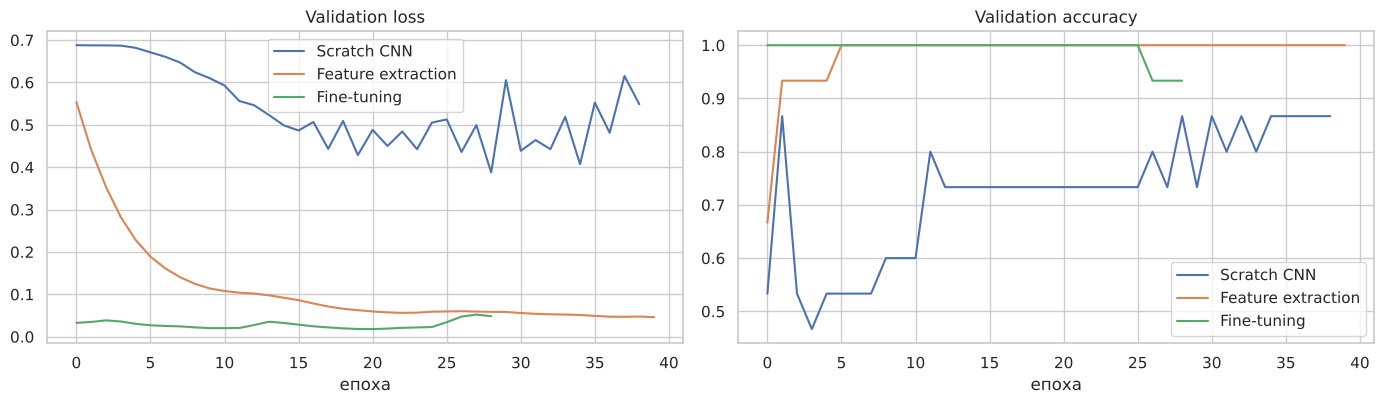

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for name, h in histories.items():
    axes[0].plot(h["val_loss"], label=name); axes[1].plot(h["val_accuracy"], label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for ax in axes: ax.set_xlabel("епоха"); ax.legend()
plt.tight_layout(); plt.show()

In [8]:
# Вибір за val loss серед двох transfer-стратегій (за рівності accuracy — менше trainable параметрів)
val_loss = {}
for name, w in [("Feature extraction", fe_weights), ("Fine-tuning", ft_weights)]:
    tl.set_weights(w); val_loss[name] = tl.evaluate(X_val, y_val, verbose=0)[0]
chosen = min(val_loss, key=val_loss.get)
tl.set_weights(fe_weights if chosen == "Feature extraction" else ft_weights)
print("Val loss:", {k: round(v, 4) for k, v in val_loss.items()}, "→ обрано:", chosen)

Val loss: {'Feature extraction': 0.0461, 'Fine-tuning': 0.0179} → обрано: Fine-tuning


## A.6. Фінальна оцінка на незалежному test (папка `val` репозиторію)

In [9]:
test_rows = []
for name, model in [("Scratch CNN", scratch), (f"MobileNetV2 — {chosen}", tl)]:
    acc, f1, p = scores(model, X_test, y_test)
    test_rows.append({"Модель": name, "Test accuracy": acc, "Test F1 (urban)": f1})
    if model is tl: p_final = p
pd.DataFrame(test_rows).set_index("Модель").round(3)

,Test accuracy,Test F1 (urban)
Модель,,
Scratch CNN,0.85,0.87
MobileNetV2 — Fine-tuning,1.00,1.00


              precision    recall  f1-score   support

       rural      1.000     1.000     1.000        10
       urban      1.000     1.000     1.000        10

    accuracy                          1.000        20
   macro avg      1.000     1.000     1.000        20
weighted avg      1.000     1.000     1.000        20



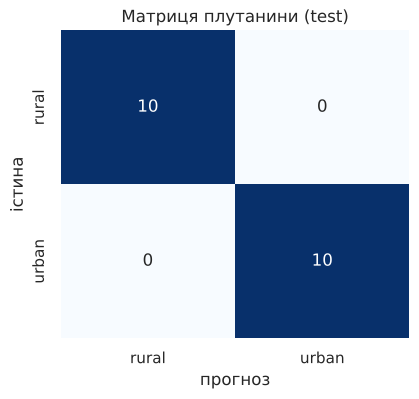

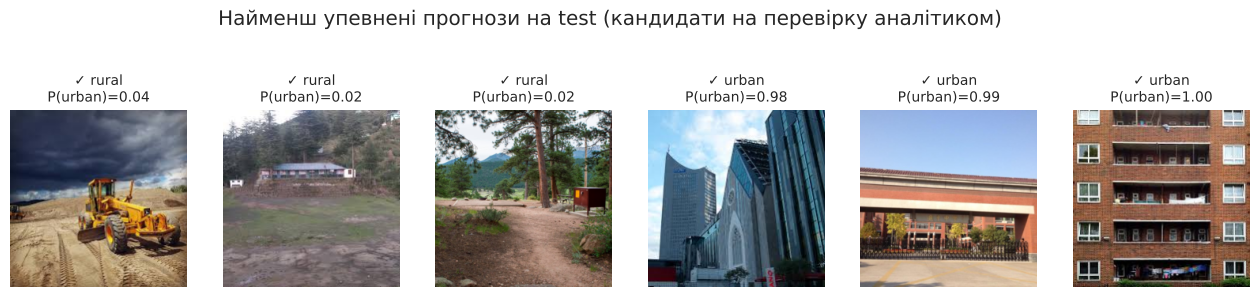

In [10]:
y_hat = (p_final >= 0.5).astype(int)
print(classification_report(y_test, y_hat, target_names=CLASSES, digits=3))
plt.figure(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(y_test, y_hat), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Матриця плутанини (test)"); plt.xlabel("прогноз"); plt.ylabel("істина"); plt.show()

order = np.argsort(np.abs(p_final - 0.5))[:6]     # найменш впевнені прогнози

fig, axes = plt.subplots(1, 6, figsize=(16, 3.4))
for ax, i in zip(axes, order):
    ax.imshow(X_test[i].astype("uint8")); ax.axis("off")
    ok = "✓" if y_hat[i] == y_test[i] else "✗"
    ax.set_title(f"{ok} {CLASSES[y_test[i]]}\nP(urban)={p_final[i]:.2f}", fontsize=10)
plt.suptitle("Найменш упевнені прогнози на test (кандидати на перевірку аналітиком)", y=1.05); plt.show()

### Висновки до частини A
Висновок формулюється за таблицями вище (значення виводяться нижче автоматично).

In [11]:
best_cnn = cmp.loc["Scratch CNN", "Val acc"]
print(f"Scratch CNN: val acc = {best_cnn:.3f}; feature extraction: {cmp.loc['Feature extraction', 'Val acc']:.3f}; "
      f"fine-tuning: {cmp.loc['Fine-tuning', 'Val acc']:.3f}")
for r in test_rows:
    print(f"TEST  {r['Модель']:35s} accuracy = {r['Test accuracy']:.3f}")

Scratch CNN: val acc = 0.867; feature extraction: 1.000; fine-tuning: 1.000
TEST  Scratch CNN                         accuracy = 0.850
TEST  MobileNetV2 — Fine-tuning           accuracy = 1.000


- Попередньо навчена MobileNetV2 з репозиторію моделей безпомилково класифікувала всі 20 тестових зображень; вже feature extraction (навчено лише 1 281 параметр класифікатора на 57 зображеннях) дав 100% на validation — це головна практична цінність репозиторіїв моделей: якісне рішення без великого набору даних і GPU.
- CNN, навчена з нуля на тих самих даних, суттєво поступається (test accuracy 0.85, тобто 3 помилки з 20): 57 зображень недостатньо, щоб вивчити корисні візуальні ознаки.
- Feature extraction і fine-tuning обидва дали 100% на validation; fine-tuning верхніх 30 шарів трохи зменшив validation loss (0.046 → 0.018), тому за зафіксованим правилом обрано його. При цьому він навчає ~1.5 млн параметрів на 57 зображеннях — ризик перенавчання значно вищий, тож на такій малій вибірці різниця між стратегіями фактично в межах шуму.
- **Обмеження:** test містить лише 20 зображень (1 помилка = 5 п.п. accuracy); зображення з інтернету можуть відрізнятися від реальних аерознімків/знімків з БпЛА — перед практичним використанням потрібна перевірка на цільовому домені.

---
# Частина B. Reinforcement Learning: оптимізація логістичного маршруту

## B.1. Постановка задачі (групова частина)
Колона постачання має дістатися з **бази (S)** до **підрозділу (G)** на карті 8×8 клітинок.
- **█ Непрохідна місцевість** (ріка, болото) — рух неможливий.
- **☢ Небезпечні зони** (зона ураження противника) — прохід можливий, але зі штрафом −10.
- Кожен крок коштує −1 (час/пальне), досягнення мети +30. Ліміт — 60 кроків.

Агент не знає карти — він має сам навчитися маршруту, що **максимізує сумарну винагороду**, тобто балансує довжину шляху і ризик. Для перевірки обчислюємо справжній оптимум алгоритмом Дейкстри: це дозволяє об'єктивно оцінити, чи навчився агент оптимальної політики.

**Розподіл ролей у групі (рекомендований):** середовище та функція винагороди — 1 особа; Q-learning — 1; DQN — 1–2; оцінка та порівняння з оптимумом — 1; презентація — уся група.

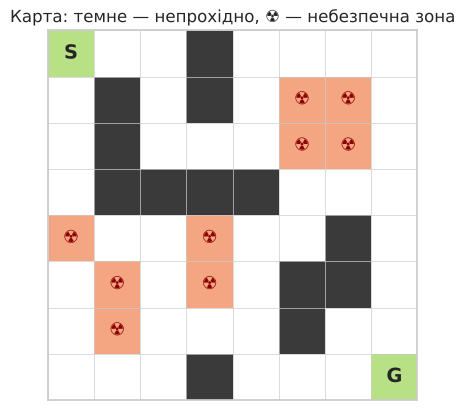

In [12]:
class SupplyRouteEnv:
    """Середовище «маршрут постачання». API як у gymnasium: reset() -> state, step(a) -> (state, r, done, info)."""
    ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}   # вгору, вниз, вліво, вправо
    NAMES = ["↑", "↓", "←", "→"]

    def __init__(self):
        self.grid = np.array([
            "S..#....",
            ".#.#.DD.",
            ".#...DD.",
            ".####...",
            "D..D..#.",
            ".D.D.##.",
            ".D...#..",
            "...#...G",
        ])
        self.n = self.grid.shape[0]
        self.start = self._find("S"); self.goal = self._find("G")
        self.n_states, self.n_actions = self.n * self.n, 4
        self.max_steps = 60

    def _find(self, ch):
        r, c = np.argwhere(np.array([list(row) for row in self.grid]) == ch)[0]
        return int(r), int(c)

    def cell(self, pos): return self.grid[pos[0]][pos[1]]
    def to_state(self, pos): return pos[0] * self.n + pos[1]

    def reset(self):
        self.pos, self.t = self.start, 0
        return self.to_state(self.pos)

    def step(self, a):
        self.t += 1
        dr, dc = self.ACTIONS[a]
        nr, nc = self.pos[0] + dr, self.pos[1] + dc
        reward = -1.0
        if 0 <= nr < self.n and 0 <= nc < self.n and self.cell((nr, nc)) != "#":
            self.pos = (nr, nc)
        else:
            reward -= 1.0                       # спроба врізатися в стіну/межу — додатковий штраф
        if self.cell(self.pos) == "D":
            reward -= 10.0
        done = self.pos == self.goal
        if done:
            reward += 30.0
        return self.to_state(self.pos), reward, done or self.t >= self.max_steps, {"reached": done}

env = SupplyRouteEnv()

def draw_map(env, path=None, ax=None, title=""):
    ax = ax or plt.gca()
    from matplotlib.colors import ListedColormap
    codes = {"#": 0, "D": 1, ".": 2, "S": 3, "G": 3}
    img = np.array([[codes[ch] for ch in row] for row in env.grid])
    cmap = ListedColormap(["#3a3a3a", "#f4a582", "#ffffff", "#b8e186"])  # стіна, небезпека, вільно, S/G
    ax.imshow(img, cmap=cmap, vmin=-0.5, vmax=3.5)
    ax.set_xticks(np.arange(-0.5, env.n), minor=True); ax.set_yticks(np.arange(-0.5, env.n), minor=True)
    ax.grid(which="minor", color="#cccccc", lw=0.5); ax.grid(which="major", visible=False)
    for r in range(env.n):
        for c in range(env.n):
            ch = env.grid[r][c]
            if ch in "SG": ax.text(c, r, ch, ha="center", va="center", fontsize=14, weight="bold")
            if ch == "D": ax.text(c, r, "☢", ha="center", va="center", fontsize=13, color="darkred")
    if path:
        ys, xs = zip(*path); ax.plot(xs, ys, "-o", color="royalblue", lw=3, ms=5)
    ax.set_xticks([]); ax.set_yticks([]); ax.tick_params(which="minor", length=0); ax.set_title(title)

draw_map(env, title="Карта: темне — непрохідно, ☢ — небезпечна зона"); plt.show()

## B.2. Еталон: оптимальний маршрут (Дейкстра)
Оскільки винагорода — це сума штрафів за клітинки + бонус за мету, максимізація винагороди = пошук найдешевшого шляху з вартістю входу в клітинку 1 (звичайна) або 11 (небезпечна).

In [13]:
import heapq
def optimal_route(env):
    cost = lambda p: 1 + (10 if env.cell(p) == "D" else 0)
    dist, prev, pq = {env.start: 0}, {}, [(0, env.start)]
    while pq:
        d, p = heapq.heappop(pq)
        if p == env.goal: break
        for dr, dc in env.ACTIONS.values():
            q = (p[0] + dr, p[1] + dc)
            if 0 <= q[0] < env.n and 0 <= q[1] < env.n and env.cell(q) != "#" and d + cost(q) < dist.get(q, 1e9):
                dist[q], prev[q] = d + cost(q), p
                heapq.heappush(pq, (d + cost(q), q))
    path, p = [env.goal], env.goal
    while p != env.start: p = prev[p]; path.append(p)
    return path[::-1], 30 - dist[env.goal]

opt_path, opt_return = optimal_route(env)
print(f"Оптимальний маршрут: {len(opt_path) - 1} кроків, максимальна винагорода = {opt_return:.0f}")

Оптимальний маршрут: 18 кроків, максимальна винагорода = 12


## B.3. Агент 1 — табличний Q-learning
Оновлення: $Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$, ε-жадібна стратегія дослідження з поступовим зменшенням ε.

In [14]:
def run_greedy(env, policy_fn):
    s, total, path = env.reset(), 0.0, [env.start]
    for _ in range(env.max_steps):
        s, r, done, info = env.step(policy_fn(s))
        total += r; path.append(env.pos)
        if done: return total, path, info["reached"]
    return total, path, False

rng = np.random.default_rng(SEED)
Q = np.zeros((env.n_states, env.n_actions))
alpha, gamma = 0.2, 0.97
eps, eps_min, eps_decay = 1.0, 0.02, 0.995
EPISODES = 1500
q_returns = []
t0 = time.time()
for ep in range(EPISODES):
    s, done, total = env.reset(), False, 0.0
    while not done:
        a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
        s2, r, done, info = env.step(a)
        target = r if info["reached"] else r + gamma * Q[s2].max()
        Q[s, a] += alpha * (target - Q[s, a])
        s, total = s2, total + r
    eps = max(eps_min, eps * eps_decay)
    q_returns.append(total)
q_time = time.time() - t0
q_return, q_path, q_ok = run_greedy(env, lambda s: int(np.argmax(Q[s])))
print(f"Q-learning: {EPISODES} епізодів за {q_time:.1f} с | жадібна політика: винагорода {q_return:.0f}, "
      f"кроків {len(q_path) - 1}, мета досягнута: {q_ok}")

Q-learning: 1500 епізодів за 0.2 с | жадібна політика: винагорода 6, кроків 14, мета досягнута: True


### B.3a. Контрольований експеримент: чи достатньо дослідження?
Порівняємо жадібну політику після навчання для 5 seeds при трьох налаштуваннях (змінюється **один** фактор):
базове (ε-decay 0.995, 1500 епізодів), повільніше зменшення ε (0.998, 3000 епізодів), «оптимістична» ініціалізація Q = +30 (стимулює пробувати невідомі дії).

In [15]:
def q_learning(eps_decay=0.995, episodes=1500, init=0.0, seed=SEED):
    r_ = np.random.default_rng(seed); Qx = np.full((env.n_states, env.n_actions), float(init)); e = 1.0
    for _ in range(episodes):
        s, done = env.reset(), False
        while not done:
            a = r_.integers(4) if r_.random() < e else int(np.argmax(Qx[s]))
            s2, r, done, info = env.step(a)
            Qx[s, a] += alpha * ((r if info["reached"] else r + gamma * Qx[s2].max()) - Qx[s, a]); s = s2
        e = max(eps_min, e * eps_decay)
    return run_greedy(env, lambda s: int(np.argmax(Qx[s])))[0]

seeds = range(42, 47)
exp_rows = []
for name, kw in [("базове: ε-decay 0.995, 1500 еп.", {}),
                 ("повільніше ε: 0.998, 3000 еп.", {"eps_decay": 0.998, "episodes": 3000}),
                 ("оптимістична ініціалізація Q=+30", {"init": 30.0})]:
    rets = [q_learning(seed=sd, **kw) for sd in seeds]
    exp_rows.append({"Налаштування": name, "Винагорода по seeds": rets,
                     "Знайдено оптимум": f"{sum(r == opt_return for r in rets)}/{len(rets)}"})
pd.DataFrame(exp_rows).set_index("Налаштування")

,Винагорода по seeds,Знайдено оптимум
Налаштування,,
"базове: ε-decay 0.995, 1500 еп.","[6.0, 12.0, 12.0, 12.0, 12.0]",4/5
"повільніше ε: 0.998, 3000 еп.","[12.0, 12.0, 12.0, 12.0, 12.0]",5/5
оптимістична ініціалізація Q=+30,"[12.0, 12.0, 12.0, 12.0, 12.0]",5/5


## B.4. Агент 2 — Deep Q-Network (DQN)
Замість таблиці Q-функцію апроксимує нейронна мережа (вхід — one-hot стан 64, два шари по 64, вихід — 4 Q-значення). Ключові елементи DQN:
- **Experience replay** — буфер переходів, навчання на випадкових міні-батчах (руйнує кореляцію послідовних кроків);
- **Target network** — копія мережі для обчислення цілей $r + \gamma \max Q_{target}(s',a')$, оновлюється кожні 200 кроків (стабілізує навчання);
- функція втрат Huber, оптимізатор Adam.

Табличний підхід на 64 станах працює ідеально; DQN тут потрібен, щоб показати метод, який масштабується на великі/неперервні простори станів (реальні карти, координати, швидкість, пальне), де таблиця неможлива.

In [16]:
keras.utils.set_random_seed(SEED)
def make_qnet():
    return keras.Sequential([layers.Input((env.n_states,)), layers.Dense(64, activation="relu"),
                             layers.Dense(64, activation="relu"), layers.Dense(env.n_actions)])

qnet, target_net = make_qnet(), make_qnet()
target_net.set_weights(qnet.get_weights())
opt = keras.optimizers.Adam(1e-3)
huber = keras.losses.Huber()
I = np.eye(env.n_states, dtype="float32")

@tf.function
def train_step(s, a, r, s2, d):
    q_next = tf.reduce_max(target_net(s2), axis=1)
    y = r + gamma * q_next * (1.0 - d)
    with tf.GradientTape() as tape:
        q = tf.reduce_sum(qnet(s) * tf.one_hot(a, env.n_actions), axis=1)
        loss = huber(y, q)
    opt.apply_gradients(zip(tape.gradient(loss, qnet.trainable_variables), qnet.trainable_variables))
    return loss

@tf.function
def q_values(s): return qnet(s)

BUF, BATCH, TARGET_EVERY, WARMUP = 10000, 64, 200, 500
buf = {k: np.zeros(BUF, dtype=t) for k, t in [("s", "int32"), ("a", "int32"), ("r", "float32"), ("s2", "int32"), ("d", "float32")]}
n_buf, step = 0, 0
eps, DQN_EPISODES = 1.0, 500
dqn_returns = []
t0 = time.time()
for ep in range(DQN_EPISODES):
    s, done, total = env.reset(), False, 0.0
    while not done:
        a = int(rng.integers(4)) if rng.random() < eps else int(np.argmax(q_values(I[[s]])[0]))
        s2, r, done, info = env.step(a)
        i = n_buf % BUF
        buf["s"][i], buf["a"][i], buf["r"][i], buf["s2"][i], buf["d"][i] = s, a, r, s2, float(info["reached"])
        n_buf, step, s, total = n_buf + 1, step + 1, s2, total + r
        if n_buf >= WARMUP:
            idx = rng.integers(0, min(n_buf, BUF), BATCH)
            train_step(I[buf["s"][idx]], buf["a"][idx], buf["r"][idx], I[buf["s2"][idx]], buf["d"][idx])
        if step % TARGET_EVERY == 0:
            target_net.set_weights(qnet.get_weights())
    eps = max(0.02, eps * 0.99)
    dqn_returns.append(total)
dqn_time = time.time() - t0
dqn_return, dqn_path, dqn_ok = run_greedy(env, lambda s: int(np.argmax(q_values(I[[s]])[0])))
print(f"DQN: {DQN_EPISODES} епізодів, {step} кроків середовища за {dqn_time:.0f} с | жадібна політика: "
      f"винагорода {dqn_return:.0f}, кроків {len(dqn_path) - 1}, мета досягнута: {dqn_ok}")

DQN: 500 епізодів, 12664 кроків середовища за 24 с | жадібна політика: винагорода 12, кроків 18, мета досягнута: True


## B.5. Порівняння агентів з оптимумом

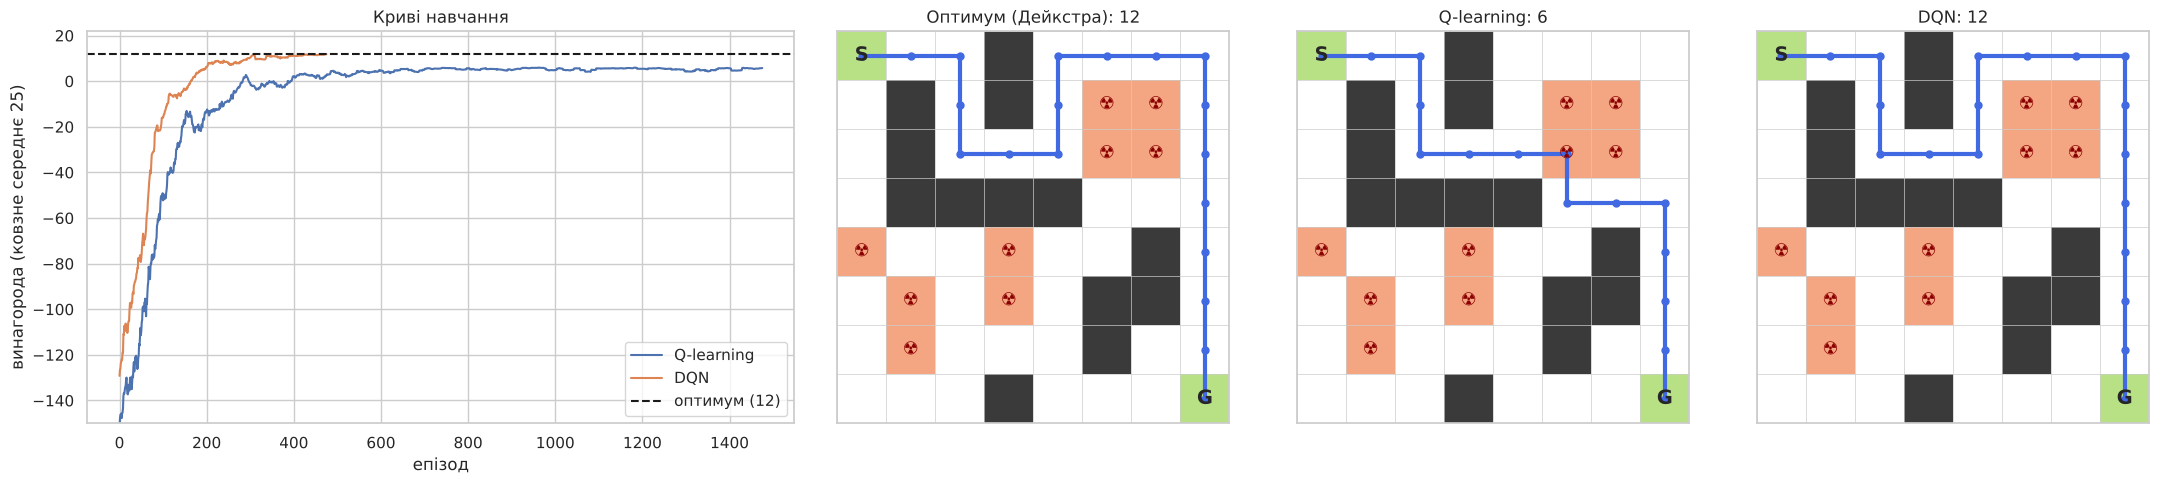

In [17]:
smooth = lambda x, w=25: np.convolve(x, np.ones(w) / w, mode="valid")
fig, axes = plt.subplots(1, 4, figsize=(22, 5), gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
axes[0].plot(smooth(q_returns), label="Q-learning")
axes[0].plot(smooth(dqn_returns), label="DQN")
axes[0].axhline(opt_return, color="k", ls="--", label=f"оптимум ({opt_return:.0f})")
axes[0].set_ylim(-150, opt_return + 10); axes[0].set_xlabel("епізод"); axes[0].set_ylabel("винагорода (ковзне середнє 25)")
axes[0].set_title("Криві навчання"); axes[0].legend()
draw_map(env, opt_path, axes[1], f"Оптимум (Дейкстра): {opt_return:.0f}")
draw_map(env, q_path, axes[2], f"Q-learning: {q_return:.0f}")
draw_map(env, dqn_path, axes[3], f"DQN: {dqn_return:.0f}")
plt.tight_layout(); plt.show()

In [18]:
def danger_cells(path): return sum(env.cell(p) == "D" for p in path)
rl = pd.DataFrame([
    {"Метод": "Дейкстра (еталон, знає карту)", "Винагорода": opt_return, "Кроків": len(opt_path) - 1,
     "Небезпечних клітинок": danger_cells(opt_path), "Мета": True, "Навчання, с": 0},
    {"Метод": "Q-learning", "Винагорода": q_return, "Кроків": len(q_path) - 1,
     "Небезпечних клітинок": danger_cells(q_path), "Мета": q_ok, "Навчання, с": round(q_time, 1)},
    {"Метод": "DQN", "Винагорода": dqn_return, "Кроків": len(dqn_path) - 1,
     "Небезпечних клітинок": danger_cells(dqn_path), "Мета": dqn_ok, "Навчання, с": round(dqn_time, 1)},
]).set_index("Метод")
rl

,Винагорода,Кроків,Небезпечних клітинок,Мета,"Навчання, с"
Метод,,,,,
"Дейкстра (еталон, знає карту)",12.0,18,0,True,0.0
Q-learning,6.0,14,1,True,0.2
DQN,12.0,18,0,True,23.5


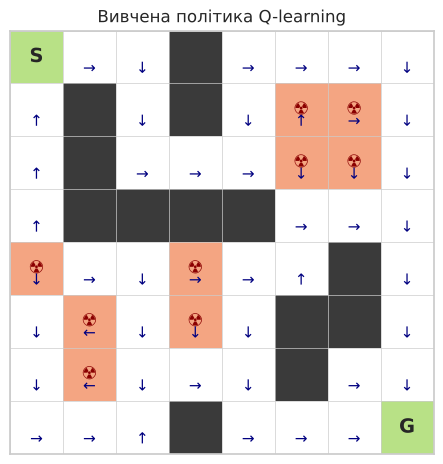

In [19]:
# Політика Q-learning: найкраща дія в кожній клітинці
fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_map(env, ax=ax, title="Вивчена політика Q-learning")
for r in range(env.n):
    for c in range(env.n):
        if env.grid[r][c] in ".D" :
            ax.text(c, r + 0.3, env.NAMES[int(np.argmax(Q[env.to_state((r, c))]))], ha="center", fontsize=11, color="navy")
plt.show()

### Висновки до частини B
- Обидва агенти, **не знаючи карти**, навчилися доводити колону до мети. **DQN** знайшов оптимальний маршрут (18 кроків, 0 небезпечних клітинок, винагорода 12 — збігається з еталоном Дейкстри).
- **Q-learning** з базовими налаштуваннями (seed 42) зійшовся до **субоптимального ризикованого маршруту**: 14 кроків, але через небезпечну зону (винагорода 6). Контрольований експеримент B.3a показує причину — **недостатнє дослідження**: базове налаштування знаходить оптимум у 4 з 5 seeds, а повільніше зменшення ε або оптимістична ініціалізація — у 5 з 5. Висновок для практики: результат RL-агента треба перевіряти на кількох seeds і, де можливо, порівнювати з еталоном.
- Оптимальний агент «зрозумів» компроміс, закладений у функції винагороди: обхід небезпечної зони (+4 кроки) вигідніший за короткий шлях через неї (штраф −10). **Поведінку агента визначає функція винагороди** — якщо неправильно оцінити ризик, агент оптимізуватиме не те, що потрібно командиру. Це головне аналітичне застереження щодо RL.
- Q-learning на 64 станах навчається за частки секунди; DQN потребує на два порядки більше часу і більше налаштувань (replay, target network, ε), але лише він масштабується на реалістичні простори станів.
- **Обмеження:** статична карта; детерміновані переходи; немає дій противника. Наступні кроки: стохастичні загрози, кілька колон (multi-agent), обмеження пального, перенесення політики на реальні геодані з обов'язковим людським контролем рішення.

---
## Загальний підсумок заняття 4.13
1. **Репозиторії моделей** (Keras Applications / TF Hub / PyTorch Hub) дозволяють за хвилини на CPU отримати якісний класифікатор з кількох десятків зображень — недосяжно для моделі «з нуля».
2. **Fine-tuning** — не автоматично кращий за feature extraction: на малих даних його доцільність треба перевіряти на validation.
3. **RL** придатне для задач послідовного прийняття рішень (маршрути, логістика), але якість рішення обмежена коректністю симулятора та функції винагороди; результат обов'язково порівнювати з класичним алгоритмом-еталоном, коли він існує.